Практическая работа №8: Аналитические выводы, сравнение групп и интерпретация визуализаций

In [1]:
%pip install seaborn
%pip install openpyxl

In [2]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Настройка визуального стиля
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

data_dir = 'data' if os.path.exists('data') else '.'

# 1. Загрузка и склейка заказов
order_files = sorted(glob.glob(os.path.join(data_dir, 'orders_2024_*.csv')))
df_orders = pd.concat([pd.read_csv(f) for f in order_files], ignore_index=True)
df_orders['order_datetime'] = pd.to_datetime(df_orders['order_datetime'])
df_orders['revenue'] = df_orders['price'] * df_orders['quantity']

# 2. Подгрузка справочника товаров
df_products = pd.read_excel(os.path.join(data_dir, 'products.xlsx'))
df_merged = df_orders.merge(df_products, on='product_id', how='left')

print(f'Всего обработано заказов: {len(df_orders):,}')

Всего обработано заказов: 15,000


In [3]:
table1 = (
    df_orders.groupby('status')
    .agg(
        orders_count=('order_id', 'count'),
        total_revenue=('revenue', 'sum'),
        avg_check=('revenue', 'mean'),
        avg_item_price=('price', 'mean'),
        avg_quantity=('quantity', 'mean'),
    )
    .reset_index()
)

table1['orders_share_%'] = (
    table1['orders_count'] / table1['orders_count'].sum() * 100
).round(2)
table1['revenue_share_%'] = (
    table1['total_revenue'] / table1['total_revenue'].sum() * 100
).round(2)
table1['total_revenue_mln'] = (table1['total_revenue'] / 1e6).round(2)

print('Таблица 1. Показатели по статусам заказов:')
print(
    table1[[
        'status',
        'orders_count',
        'orders_share_%',
        'total_revenue_mln',
        'revenue_share_%',
        'avg_check',
    ]].to_string(index=False)
)

Таблица 1. Показатели по статусам заказов:
   status  orders_count  orders_share_%  total_revenue_mln  revenue_share_%    avg_check
cancelled          2212           14.75              56.58            14.71 25576.792631
     paid         12032           80.21             307.83            80.05 25584.191658
 refunded           756            5.04              20.14             5.24 26638.614365


In [4]:
# Абсолютное количество
cat_status_abs = pd.crosstab(
    df_merged['category_name'],
    df_merged['status'],
    margins=True,
    margins_name='Всего',
)

# Процентное распределение внутри каждой категории
cat_status_pct = (
    pd.crosstab(
        df_merged['category_name'], df_merged['status'], normalize='index'
    )
    * 100
).round(2)

print('Таблица 2.1. Количество заказов по категориям и статусам (шт.):')
print(cat_status_abs.to_string())
print(
    '\nТаблица 2.2. Доли статусов внутри каждой категории (% от категории):'
)
print(cat_status_pct.to_string())

Таблица 2.1. Количество заказов по категориям и статусам (шт.):
status         cancelled   paid  refunded  Всего
category_name                                   
Electronics          455   2402       166   3023
Fashion              271   1628       103   2002
Home                 228   1229        74   1531
Sport                595   3115       190   3900
Toys                 663   3658       223   4544
Всего               2212  12032       756  15000

Таблица 2.2. Доли статусов внутри каждой категории (% от категории):
status         cancelled   paid  refunded
category_name                            
Electronics        15.05  79.46      5.49
Fashion            13.54  81.32      5.14
Home               14.89  80.27      4.83
Sport              15.26  79.87      4.87
Toys               14.59  80.50      4.91


In [5]:
df_orders['month'] = df_orders['order_datetime'].dt.to_period('M')

monthly_dyn = pd.crosstab(df_orders['month'], df_orders['status'])
monthly_pct = (
    pd.crosstab(df_orders['month'], df_orders['status'], normalize='index')
    * 100
).round(2)

monthly_summary = monthly_dyn.copy()
for col in ['cancelled', 'paid', 'refunded']:
  monthly_summary[f'{col}_%'] = monthly_pct[col]

print('Таблица 3. Помесячная динамика статусов:')
print(monthly_summary.to_string())

Таблица 3. Помесячная динамика статусов:
status   cancelled  paid  refunded  cancelled_%  paid_%  refunded_%
month                                                              
2024-01        725  4038       237        14.50   80.76        4.74
2024-02        769  3990       241        15.38   79.80        4.82
2024-03        718  4004       278        14.36   80.08        5.56


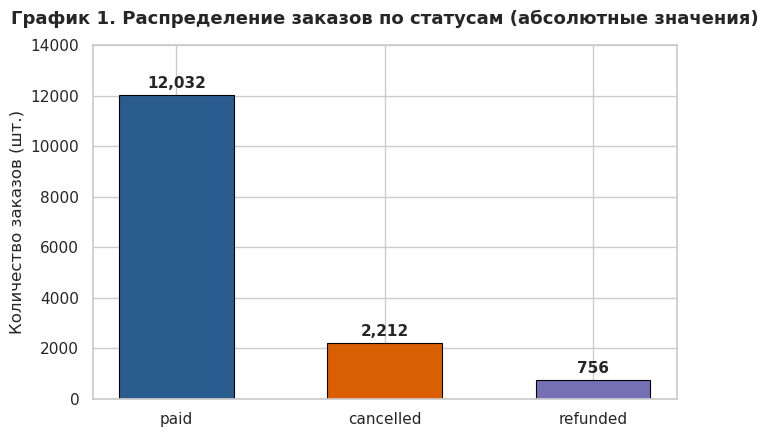

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
status_counts = df_orders['status'].value_counts()
colors = ['#2b5c8f', '#d95f02', '#7570b3']

bars = ax.bar(
    status_counts.index,
    status_counts.values,
    color=colors,
    width=0.55,
    edgecolor='black',
    linewidth=0.8,
)
for bar in bars:
  yval = bar.get_height()
  ax.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 150,
      f'{int(yval):,}',
      ha='center',
      va='bottom',
      fontweight='bold',
  )

ax.set_title(
    'График 1. Распределение заказов по статусам (абсолютные значения)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Количество заказов (шт.)')
ax.set_ylim(0, 14000)
plt.tight_layout()
plt.show()

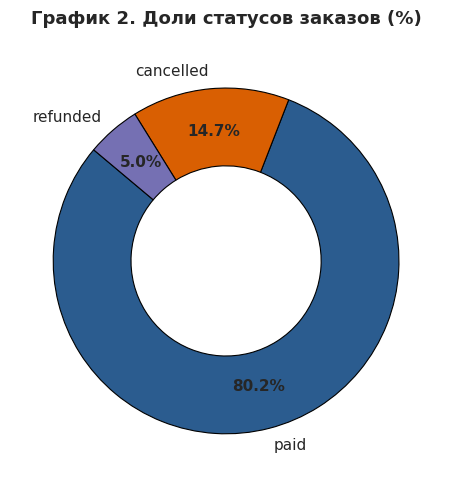

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
status_props = df_orders['status'].value_counts(normalize=True) * 100

wedges, texts, autotexts = ax.pie(
    status_props.values,
    labels=status_props.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=0.8),
)
for at in autotexts:
  at.set_fontsize(11)
  at.set_fontweight('bold')

ax.set_title(
    'График 2. Доли статусов заказов (%)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()

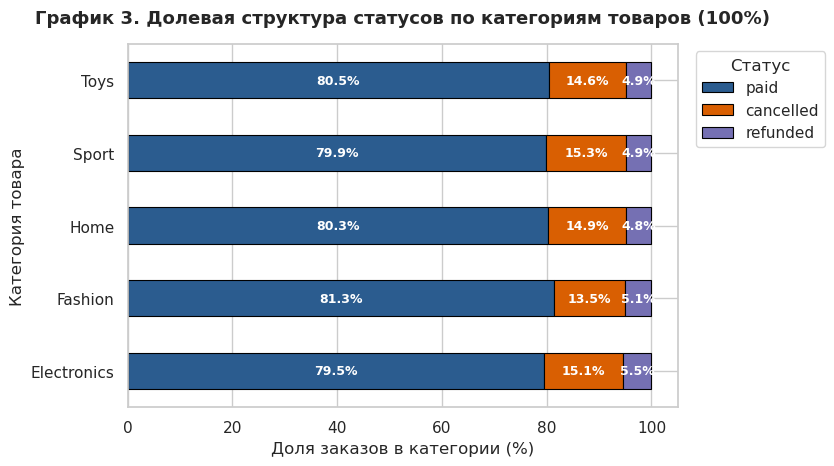

In [8]:
cross_cat = (
    pd.crosstab(
        df_merged['category_name'], df_merged['status'], normalize='index'
    )
    * 100
)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
cross_cat[['paid', 'cancelled', 'refunded']].plot(
    kind='barh',
    stacked=True,
    color=['#2b5c8f', '#d95f02', '#7570b3'],
    edgecolor='black',
    linewidth=0.8,
    ax=ax,
)

ax.set_title(
    'График 3. Долевая структура статусов по категориям товаров (100%)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Доля заказов в категории (%)')
ax.set_ylabel('Категория товара')
ax.legend(title='Статус', bbox_to_anchor=(1.02, 1), loc='upper left')

for p in ax.patches:
  width, height = p.get_width(), p.get_height()
  if width > 4:
    ax.text(
        p.get_x() + width / 2,
        p.get_y() + height / 2,
        f'{width:.1f}%',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=9,
    )

plt.tight_layout()
plt.show()

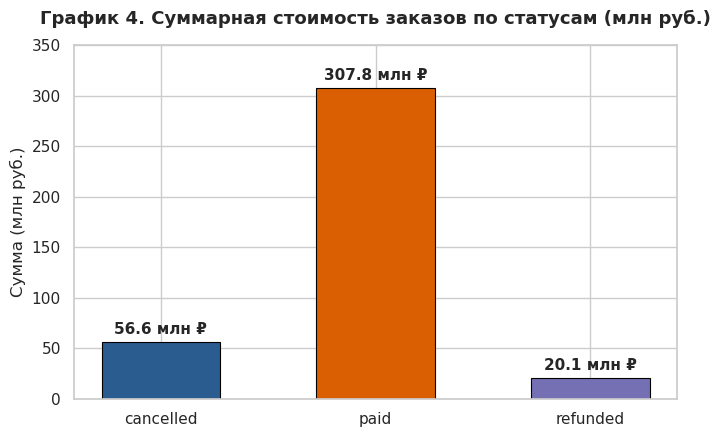

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rev_by_status = df_orders.groupby('status')['revenue'].sum() / 1e6

bars4 = ax.bar(
    rev_by_status.index,
    rev_by_status.values,
    color=colors,
    width=0.55,
    edgecolor='black',
    linewidth=0.8,
)
for bar in bars4:
  yval = bar.get_height()
  ax.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 5,
      f'{yval:.1f} млн ₽',
      ha='center',
      va='bottom',
      fontweight='bold',
  )

ax.set_title(
    'График 4. Суммарная стоимость заказов по статусам (млн руб.)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Сумма (млн руб.)')
ax.set_ylim(0, 350)
plt.tight_layout()
plt.show()

# Аналитический отчет и интерпретация результатов

---

## Ответы на теоретико-методические вопросы

### Задание 3. Сравнение абсолютных значений и долей

* **Искажение при анализе абсолютных величин (График 1):**  
  Столбец `paid` (12 032) визуально подавляет показатели `cancelled` (2 212) и `refunded` (756), создавая ложное впечатление пренебрежимо малого объема отмен и возвратов.
* **Реальная картина при оценке долей (График 2):**  
  Относительные показатели выявляют скрытую проблему воронки: **19.79%** (практически каждый пятый заказ) не завершается успешной реализацией (14.75% отмен + 5.04% возвратов).
* **Сравнение по категориям (Таблица 2):**  
  В абсолютном выражении наибольшее число отмен зафиксировано в категориях `Toys` (663) и `Sport` (595). Однако переход к долям показывает, что уровень отмен по всем категориям одинаков и колеблется в узком диапазоне **13.5% – 15.3%**. Высокие абсолютные значения обусловлены лишь общим объемом продаж в данных категориях, а не повышенной проблемностью самих товаров.

---

### Задание 4. Зоны риска ошибочной интерпретации

1. **Оценка эффективности категорий:**  
   Прямое сравнение абсолютного числа отмен (например, 663 в `Toys` против 228 в `Home`) может привести руководство к ошибочному выводу о низком качестве товаров или проблемах логистики в категории игрушек. В действительности процент отказов в `Toys` (14.59%) даже ниже, чем в `Home` (14.89%).
2. **Расчет выручки компании (GMV vs Net Revenue):**  
   Суммирование столбца `revenue` без фильтрации по статусу дает завышенный валовый оборот — **384.55 млн ₽**. Фактическая чистая выручка бизнеса (только статус `paid`) составляет **307.83 млн ₽**. Ошибка пренебрежения статусами приводит к искажению финансовых показателей на **76.72 млн ₽** (около $20\%$).

---

### Задание 5. Типичная ошибка анализа

* **Название:** Ловушка базового уровня (*Base Rate Fallacy* / подмена относительных величин абсолютными).
* **Суть ошибки:** Сравнение абсолютных счетчиков событий между выборками разного объема без нормализации на базовый размер группы.
* **Пример:** Вывод *"Клиенты из Москвы отменяют заказы чаще, чем из Тулы"* только потому, что в Москве зафиксировано 10 000 отмен, а в Туле — 100. При этом игнорируется, что в Москве оформлен 1 000 000 заказов (доля отмен — $1\%$), а в Туле — всего 500 заказов (доля отмен — $20\%$).

---

## Аналитические выводы по данным

1. **Базовый уровень выкупаемости:**  
   Доля успешно завершенных заказов составляет **80.21%** (12 032 из 15 000). Бизнес стабильно реализует 4 из 5 создаваемых заказов.
2. **Масштаб финансовых потерь:**  
   Суммарные потери оборота от отмененных и возвращенных заказов за 3 месяца достигли **76.72 млн ₽** (56.58 млн ₽ отмены + 20.14 млн ₽ возвраты), что составляет **19.95%** от общего объема оформленных заказов.
3. **Однородность отказов по категориям:**  
   Доли `cancelled` и `refunded` практически инвариантны к типу товара: отмены составляют от **13.54%** (`Fashion`) до **15.26%** (`Sport`), а возвраты — от **4.83%** (`Home`) до **5.49%** (`Electronics`). Это свидетельствует о системных платформенных факторах, а не о локальных проблемах отдельных категорий.
4. **Специфика среднего чека по статусам:**  
   Средний чек возвращенных заказов (`refunded`) равен **26 638.61 ₽**, что на **4.1% выше**, чем у оплаченных (**25 584.19 ₽**). Более дорогие позиции подвержены возврату с чуть большей вероятностью.
5. **Временная стабильность процессов:**  
   В I квартале 2024 года доля оплат оставалась стабильной: **80.76%** (январь), **79.80%** (февраль), **80.08%** (март). При этом в марте отмечен умеренный рост доли возвратов до **5.56%** (против **4.74%** в январе), что требует контроля динамики в следующем периоде.
6. **Ключевые драйверы оборота:**  
   Категории `Toys` и `Sport` суммарно генерируют **56.3%** всех заказов платформы (4 544 и 3 900 соответственно), формируя основу валового денежного потока магазина.

---

## Ограничения проведенного анализа

* **Отсутствие причин отказов:** В данных нет поля `cancellation_reason`, что не позволяет разграничить вину магазина (брак, задержка доставки, пересорт) и поведение покупателя (импульсивный заказ, нашел дешевле).
* **Синтетический характер распределений:** В выборке присутствует строгая равномерность (ровно по 5 000 заказов в месяц, минимальные расхождения долей между категориями в пределах десятых долей процента). В реальном e-commerce сезонные колебания и различия между категориями (например, существенно более высокий процент возврата одежды) выражены сильнее.
* **Короткий горизонт наблюдений:** Анализ ограничен одним кварталом (январь — март 2024 года), что исключает возможность оценки годовой сезонности и праздничных пиков.
* **Анализ на уровне позиций, а не чеков:** Заказы представлены отдельными товарными строками. Отсутствие данных о стоимости и типе доставки (курьер / ПВЗ), а также о способе оплаты не позволяет оценить их прямое влияние на процент невыкупа.